In [1]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]
        

In [4]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.ensemble.forests import RandomForestClassifier
from LearnML.selection.split import train_test_split
from LearnML.learn_about.learn_about import learn_about_RandomForest
from LearnML.metrics.metrics import classification_report



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Path added: /home/mo/Documents/LearnML_Library


Random Forest is a supervised ensemble learning algorithm that combines multiple Decision Trees to make more accurate and robust predictions. Each tree is trained using a different bootstrap sample of the training data and considers random subsets of features when creating splits.

Key Concepts:
1. Bootstrap Sampling: Each tree receives a random sample of the training data selected with replacement.
2. Random Feature Selection: Each Decision Tree considers a random subset of features when searching for the best split.
3. Multiple Decision Trees: Many independent Decision Trees are trained and stored inside the forest.
4. Majority Voting: For classification, every tree predicts a class and the class with the most votes becomes the final prediction.

Applications:
- Customer churn prediction.
- Medical diagnosis.
- Fraud detection.
- Credit risk classification.
- General classification and regression tasks.


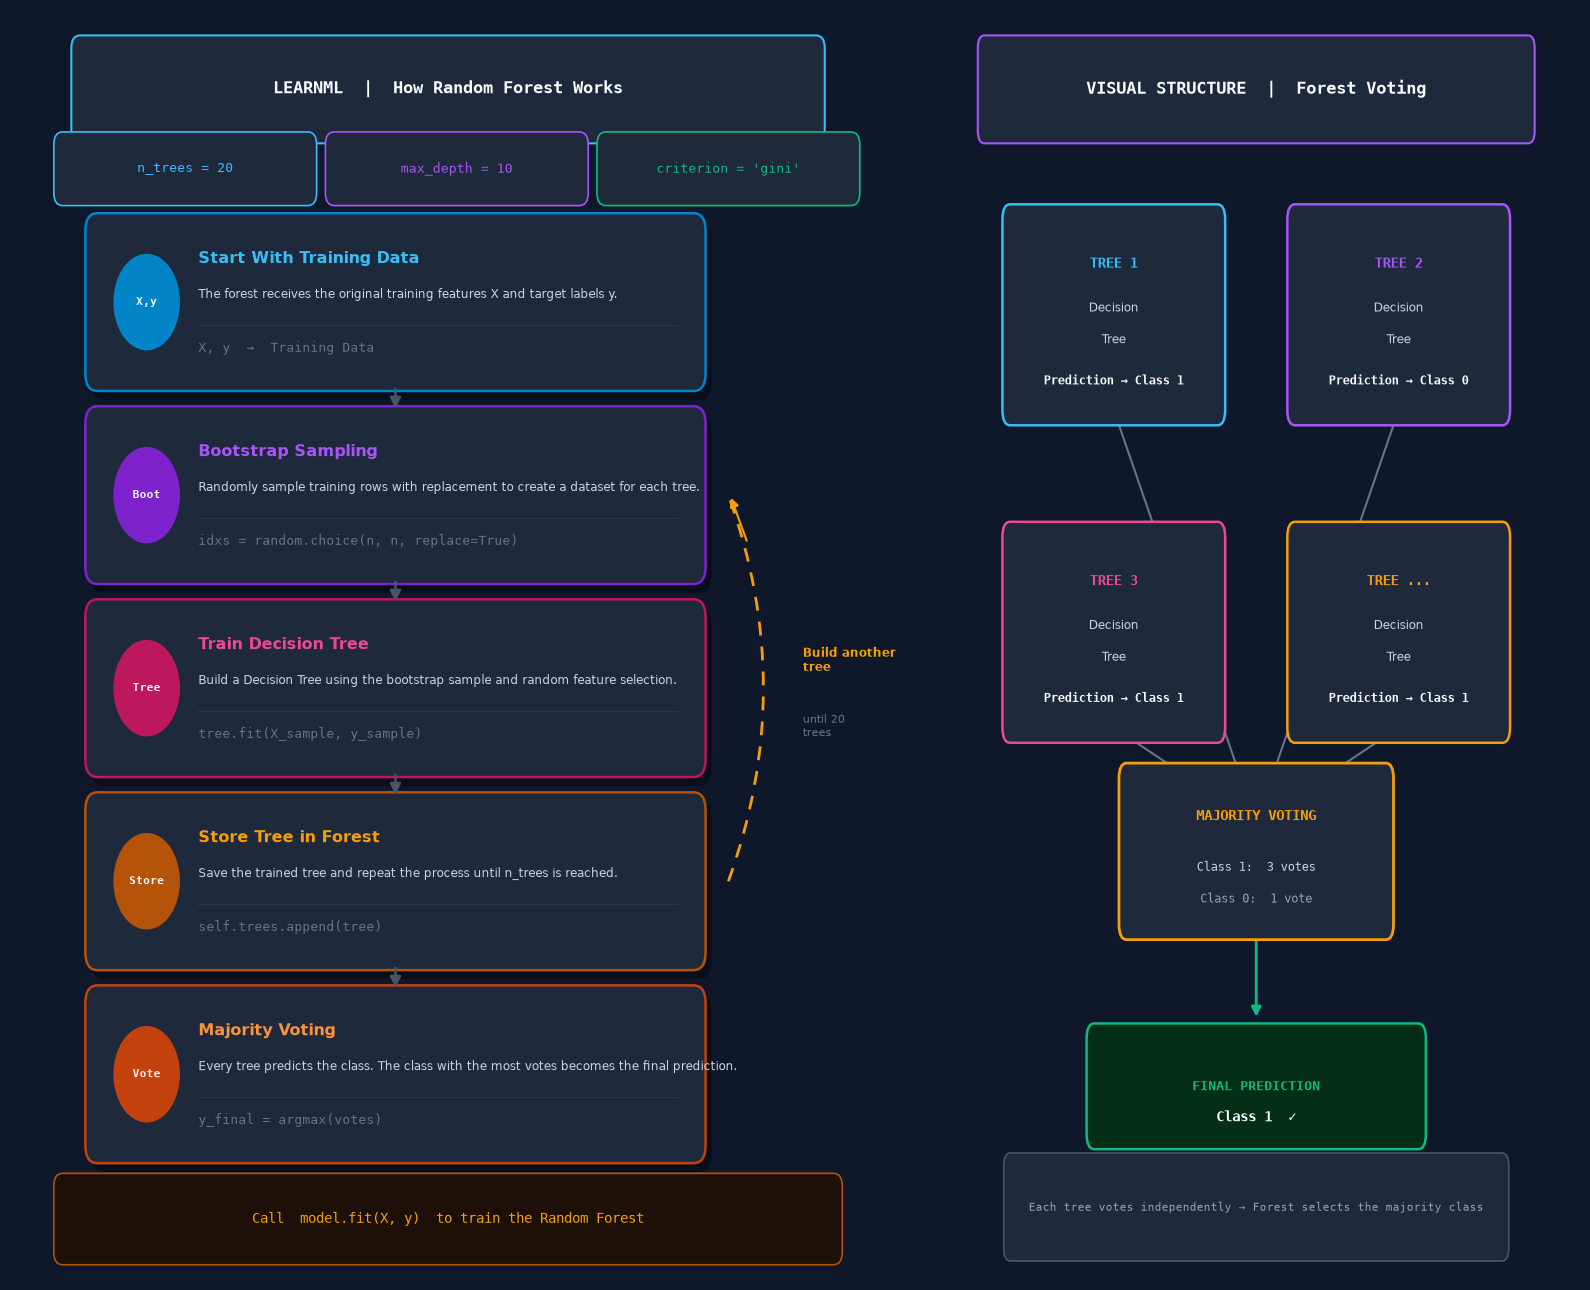

In [ ]:
learn_about_RandomForest()
    

In [9]:
from sklearn.datasets import make_classification


##1. Generate synthetic classification data (70% informative features)
X, y = make_classification(
    n_samples=1000,         # Total number of rows/samples
    n_features=10,          # Total number of input features
    n_informative=7,        # 70% pure informative features (7 out of 10)
    n_redundant=2,          # 20% redundant features (linear combinations)
    # Note: Remaining 1 feature (10%) is automatically pure random noise
    n_classes=3,            # Number of target categories (e.g., 0, 1, 2)
    n_clusters_per_class=1, # Complexity of each class distribution
    weights=[0.5, 0.3, 0.2],# Class balance (50%, 30%, 20%)
    flip_y=0.02,            # Add 2% random label noise (set to 0.0 for 100% clean labels)
    random_state=42         # Seed for reproducible results
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



Text(0.5, 1.0, 'Training Data Distribution')

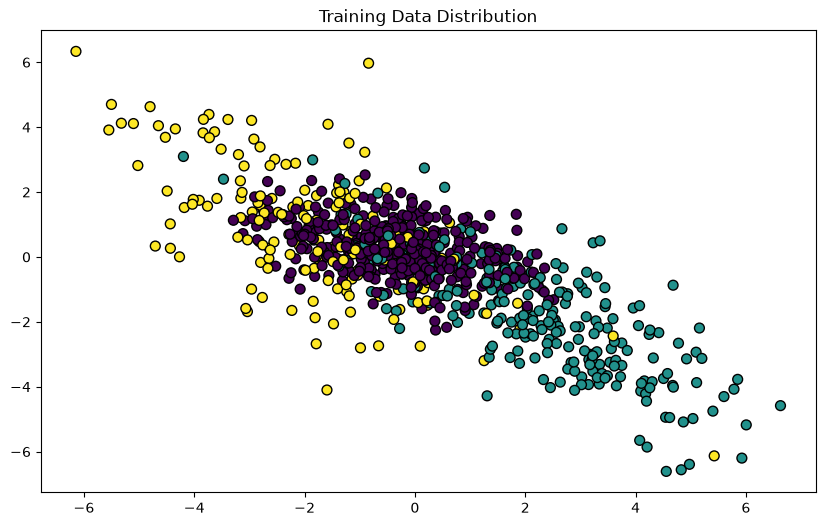

In [10]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

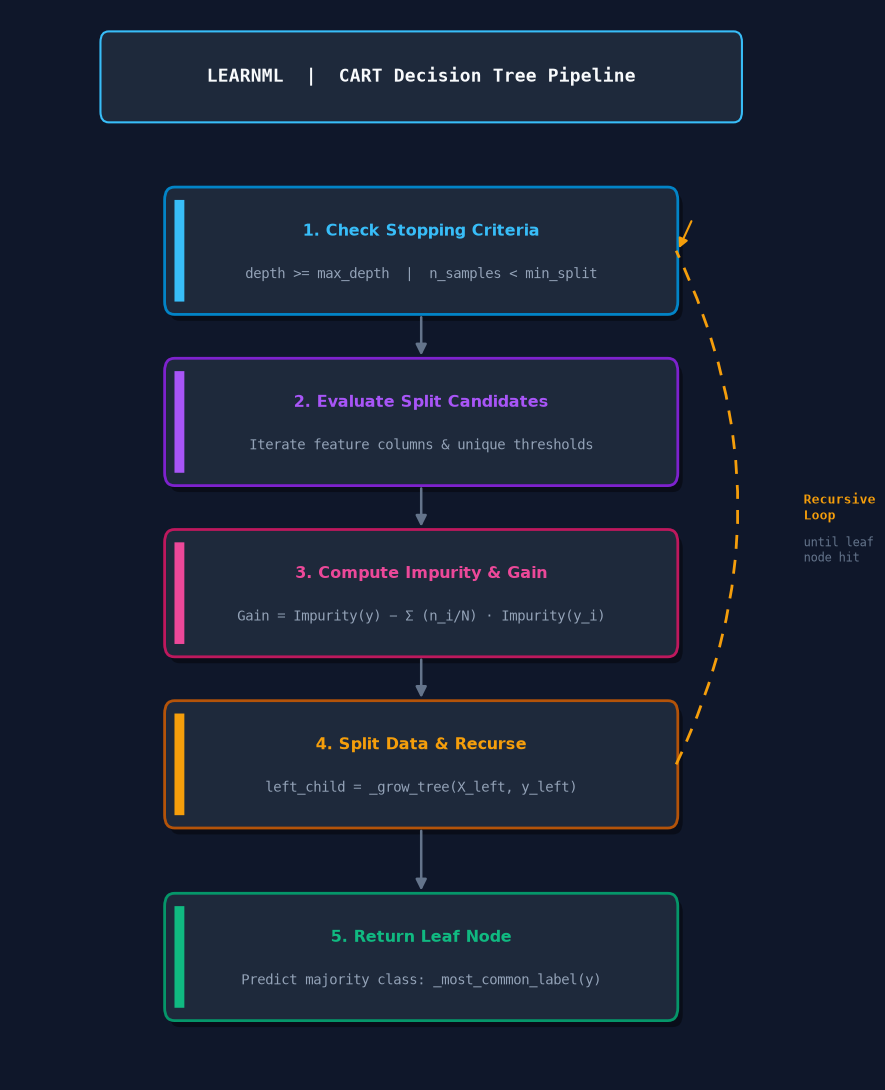

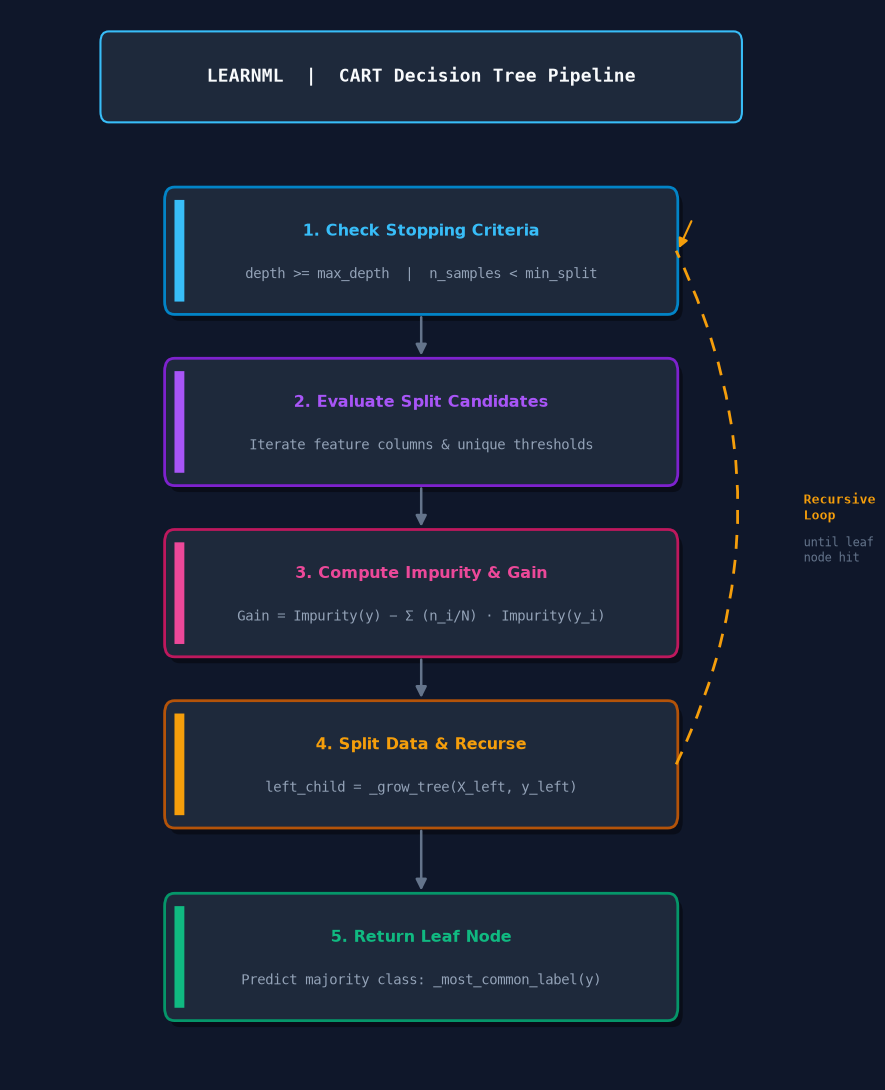

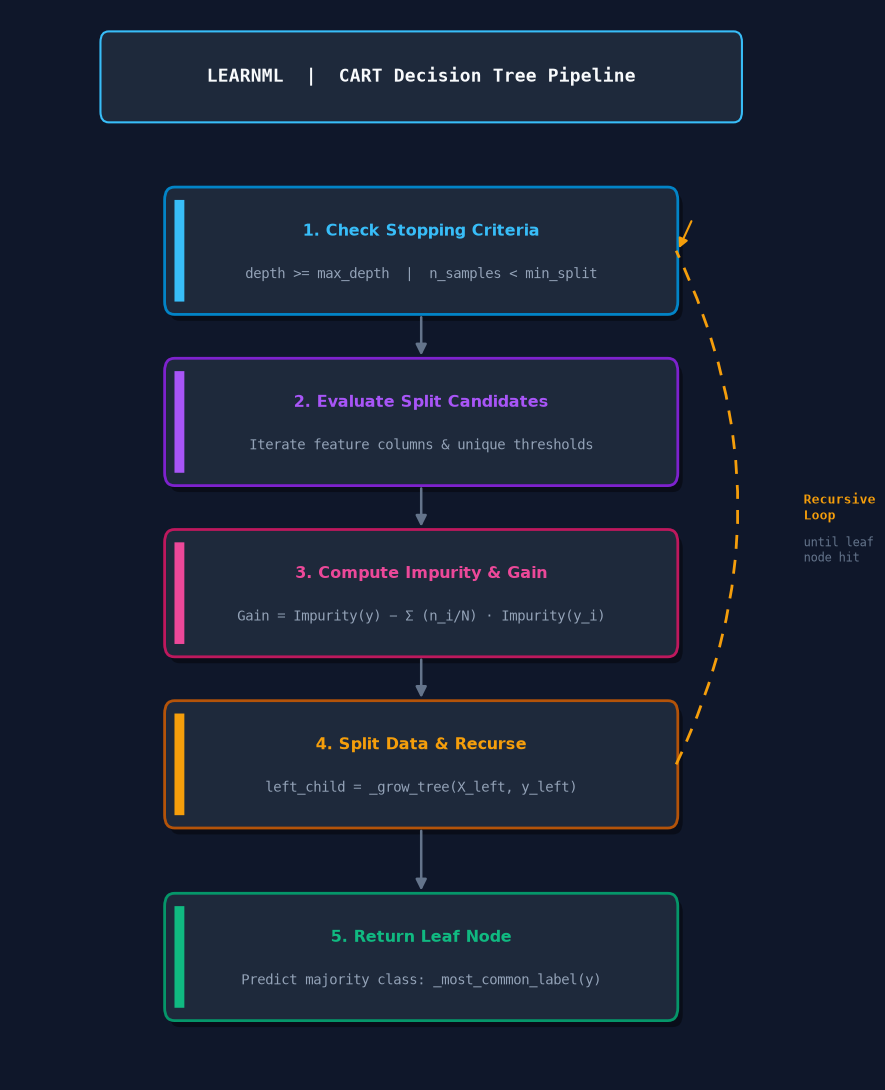

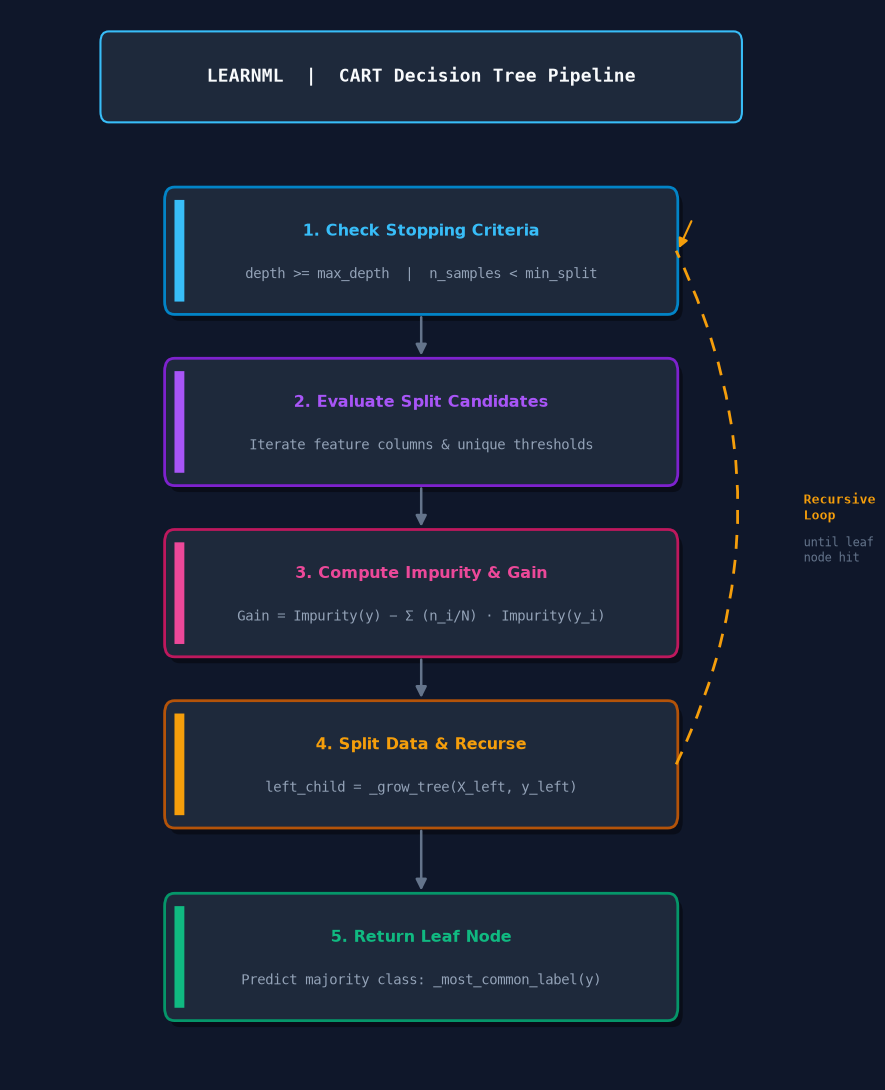

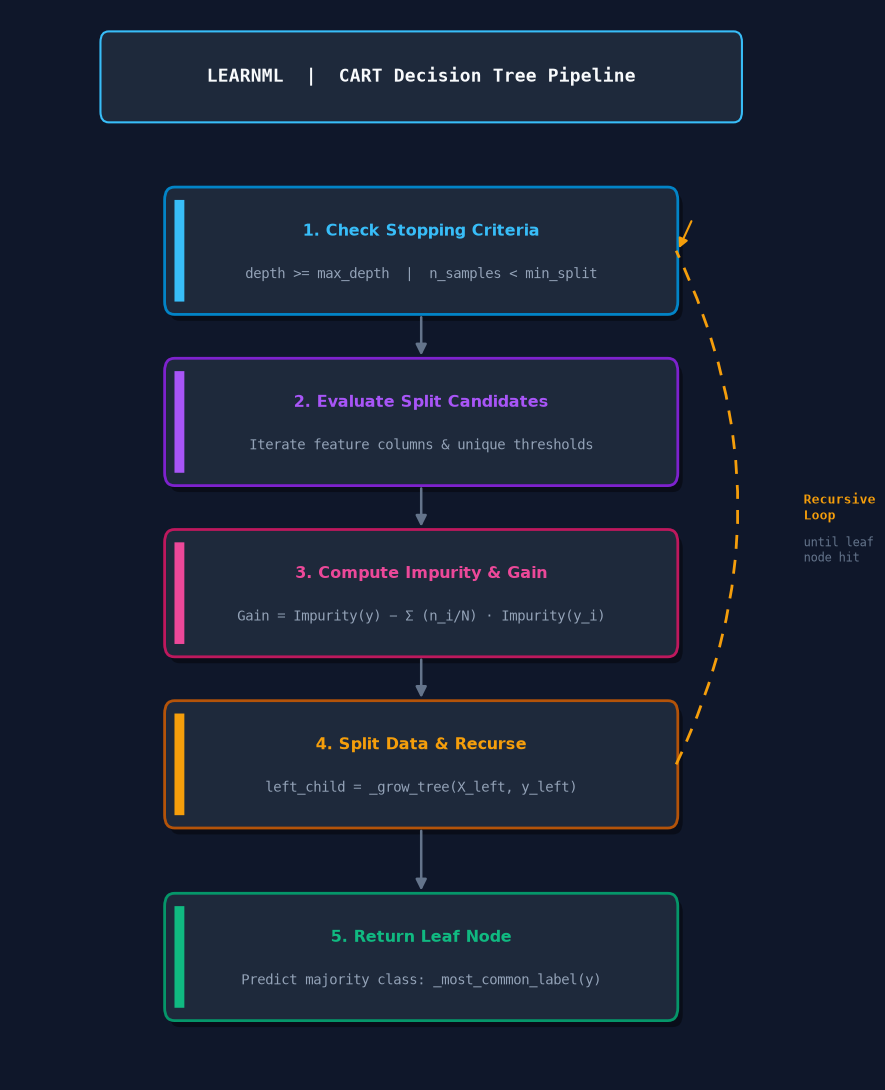

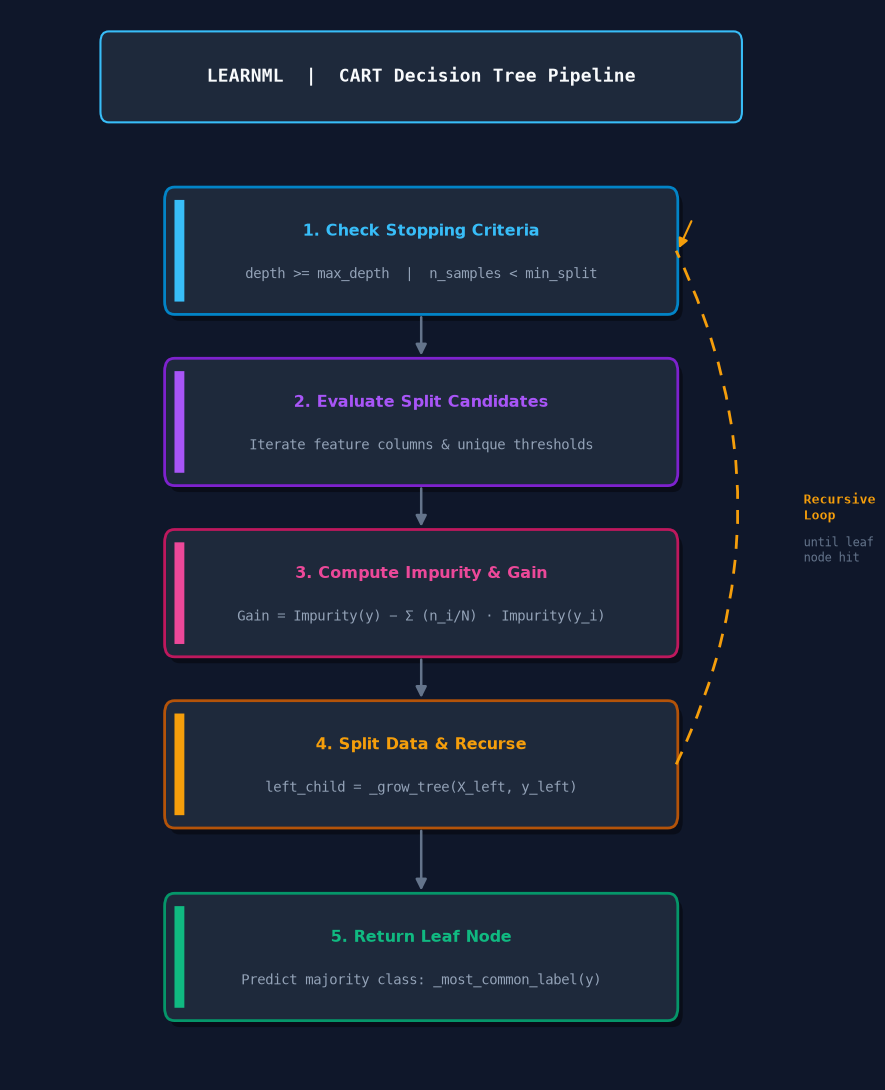

KeyboardInterrupt: 

In [11]:
rf_model=RandomForestClassifier(n_trees=20, min_samples_split=2, max_depth=10, criterion="gini")
rf_model.fit(X_train, y_train)